In [ ]:
import numpy as np
import scipy
import matplotlib.pyplot as plt
import seaborn as sns

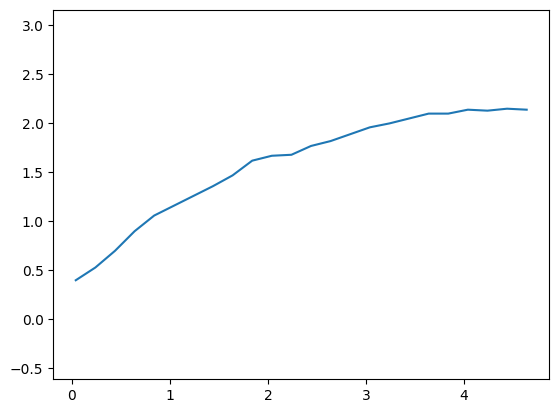

In [ ]:
stylos = '''x,y
0.04,0.4
0.24,0.53
0.44,0.7
0.64,0.9
0.84,1.06
1.04,1.16
1.24,1.26
1.44,1.36
1.64,1.47
1.84,1.62
2.04,1.67
2.24,1.68
2.44,1.77
2.64,1.82
2.84,1.89
3.04,1.96
3.24,2
3.44,2.05
3.64,2.1
3.84,2.1
4.04,2.14
4.24,2.13
4.44,2.15
4.64,2.14'''.splitlines()
data = np.genfromtxt(stylos, delimiter=',', skip_header=1)

plt.figure()
plt.axis('equal')
plt.plot(data[:,0],data[:,1])
plt.show()

In [ ]:
var_a = (np.log(2) / 1.96)**2
# posterior distribution
def posterior(theta, data):
  x = data[:,0][:,np.newaxis]
  y = data[:,1][:,np.newaxis]
  ln_a, b, var = theta
  n = data.shape[0]

  pi_ln_a = np.exp(-ln_a**2 / (2*var_a))
  pi_b = b**4 * (1-b)**4
  pi_var = 1/var

  L = np.prod(np.exp(-(np.log(y) - ln_a - b*np.log(x))**2 / (2*var)) / (y * np.sqrt(2*np.pi*var)), axis=0)

  return pi_ln_a * pi_b * pi_var * L

In [ ]:
def sample_posterior_importance(data, g='prior', size=1000):
  match g:
    case 'prior':
      ln_a = scipy.stats.norm.rvs(scale=var_a, size=size)
      b = scipy.stats.beta.rvs(4, 4, size=size)
      var = scipy.stats.gamma.rvs(1, size=size)
      x = (ln_a, b, var)
      gx = (
          scipy.stats.norm.pdf(ln_a, scale=var_a),
          scipy.stats.beta.pdf(b, 4, 4),
          # gamma rather than improper 1/x
          scipy.stats.gamma.pdf(var, 1),
      )
      w = posterior(x, data) / gx
  return x, w

In [ ]:
def sample_posterior_mh(data, proposal_dist='rw', size=1000):
  sample = np.empty((size, 3))
  log_u = np.log(scipy.stats.uniform.rvs(size=size))

  # initialise with prior means
  sample[0,:] = 0, 0.5, 0.01

  match proposal_dist:
    case 'rw':
      q = lambda theta, _: 1
      def sample_q(t):
        theta = sample[t,:] + scipy.stats.norm.rvs(scale=[0.1, 0.1, 0.01], size=3)
        theta[2] = max(0.0001, theta[2])
        return theta

  for t in range(size-1):
      proposal = sample_q(t)
      log_accept_prob = min([
          np.log(posterior(proposal, data))
            + np.log(q(sample[t,:], proposal))
            - np.log(posterior(sample[t,:], data))
            - np.log(q(proposal, sample[t,:])),
          0.0
      ])

      if log_u[t] < log_accept_prob:
        sample[t+1,:] = proposal
      else:
        sample[t+1,:] = sample[t,:]

  return sample

/tmp/ipykernel_525/1540745056.py:19: RuntimeWarning: divide by zero encountered in log
  np.log(posterior(proposal, data))


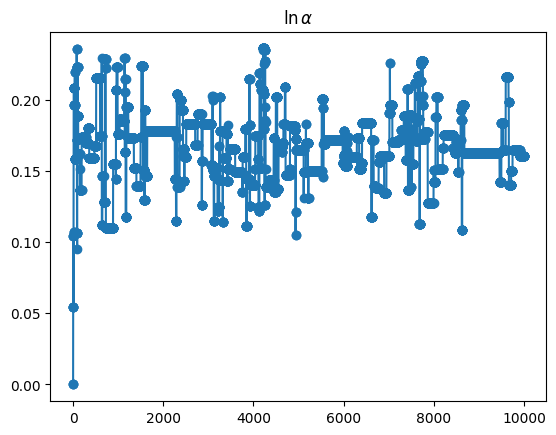

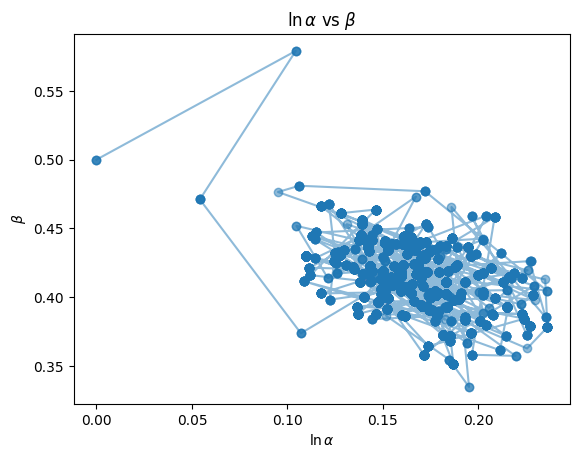

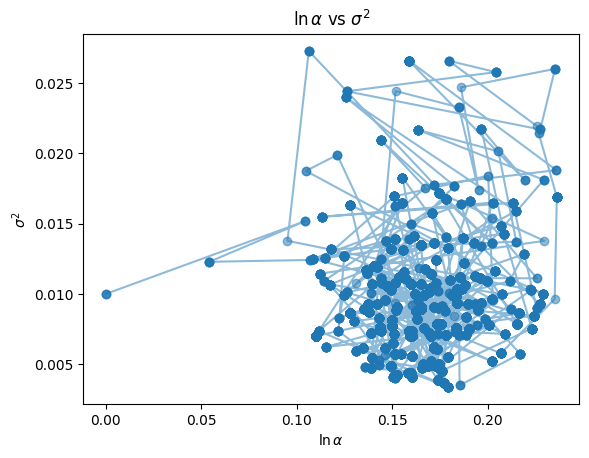

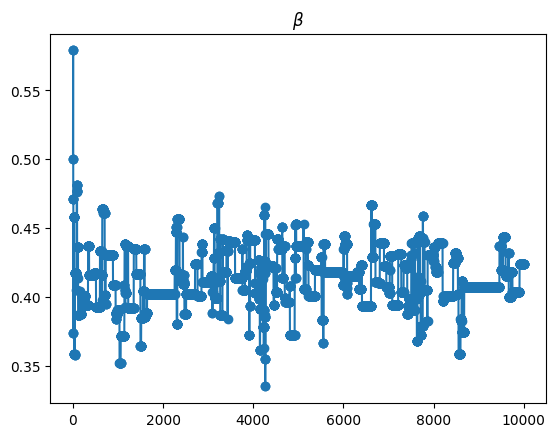

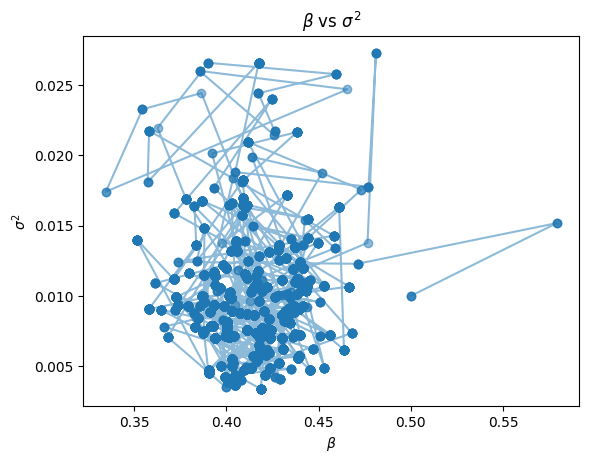

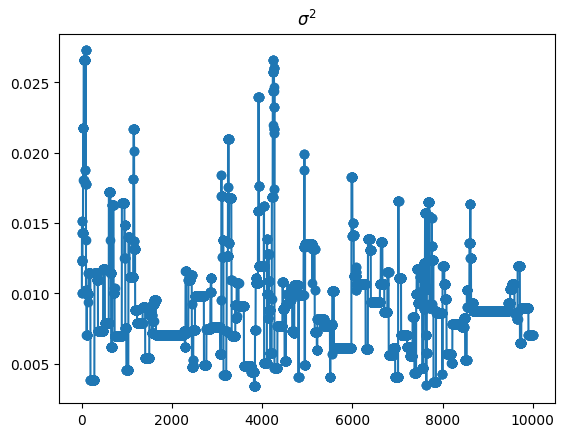

In [ ]:
xs_samples = sample_posterior_mh(data, size=10000)
labels = ['$\\ln\\alpha$', '$\\beta$', '$\\sigma^2$']

# Transpose xs_samples to iterate over columns (each parameter's history of samples)
xs_cols = xs_samples.T

for i, (label, x) in enumerate(zip(labels, xs_cols)):
  plt.plot(x, 'o-')
  plt.title(label)
  plt.show()

  # bivariates
  for j, (label2, x2) in enumerate(zip(labels[i+1:], xs_cols[i+1:])):
    plt.figure()
    plt.plot(x, x2, 'o-', alpha=0.5)
    plt.title(f'{label} vs {label2}')
    plt.xlabel(label)
    plt.ylabel(label2)
    plt.show()

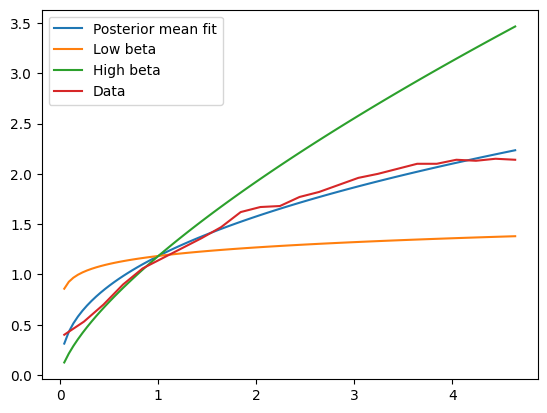

In [ ]:
ln_a_pos_mean = np.mean(xs_samples[:,0])
b_pos_mean = np.mean(xs_samples[:,1])
def model(x, ln_a, b):
  return np.exp(ln_a + b*np.log(x))

x = np.linspace(data[:,0].min(), data[:,0].max(), 100)
plt.plot(x, model(x, ln_a_pos_mean, b_pos_mean), label='Posterior mean fit')
plt.plot(x, model(x, ln_a_pos_mean, 0.1), label='Low beta')
plt.plot(x, model(x, ln_a_pos_mean, 0.7), label='High beta')
plt.plot(data[:,0], data[:,1], label='Data')
plt.legend()

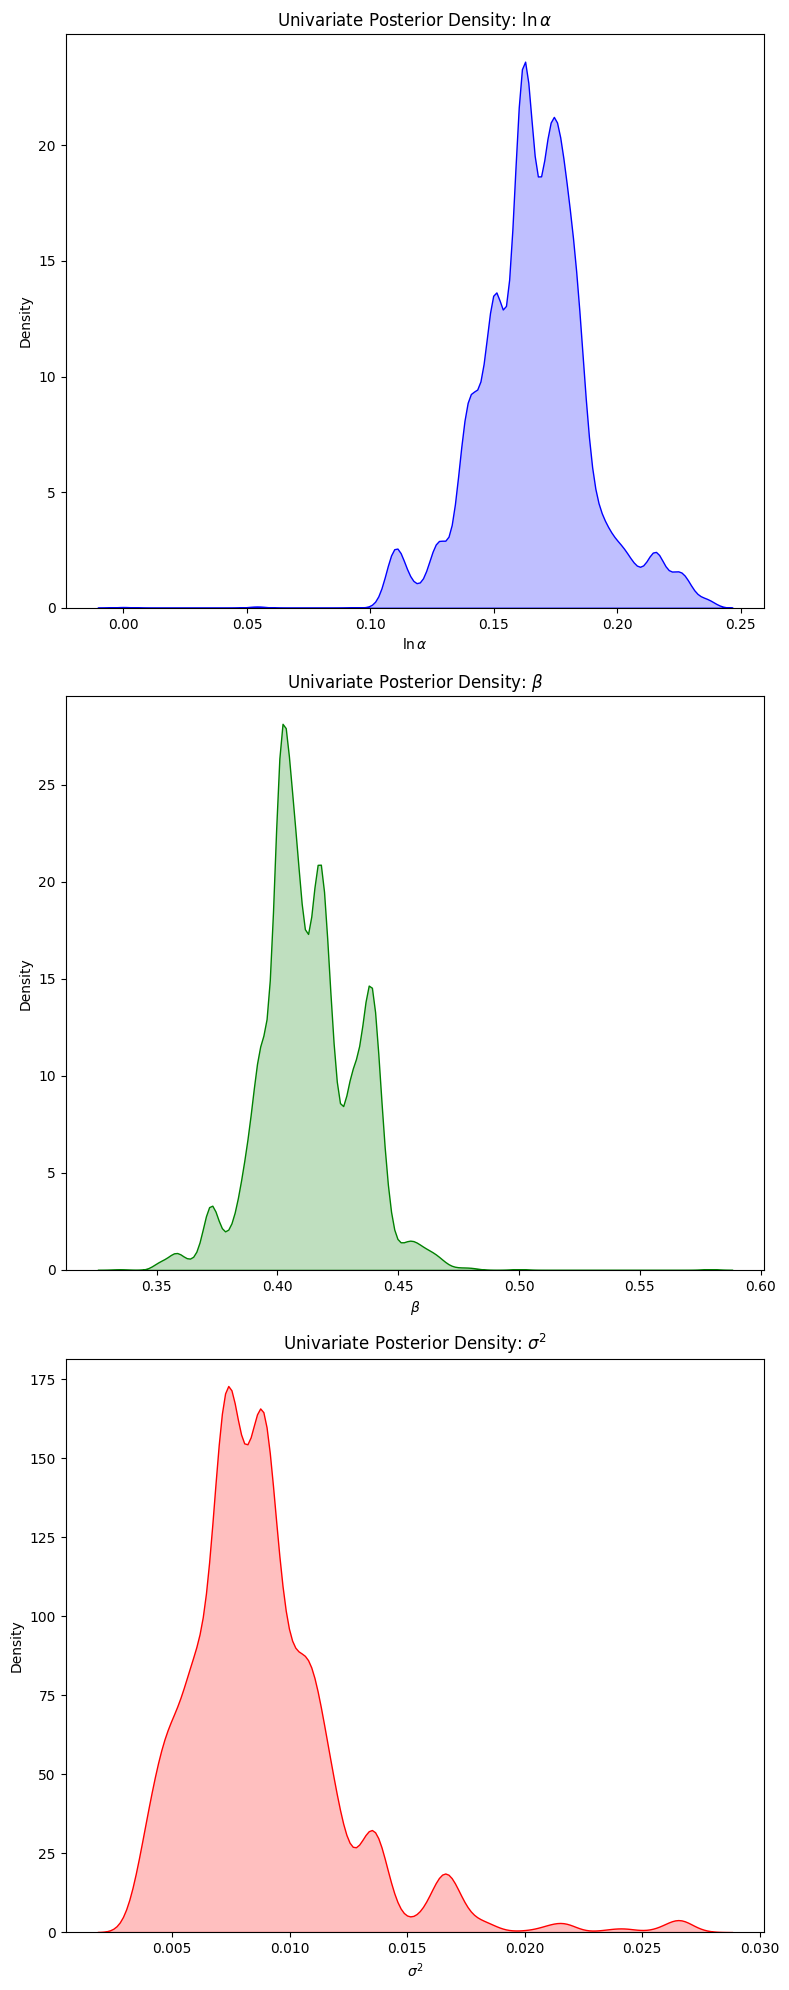

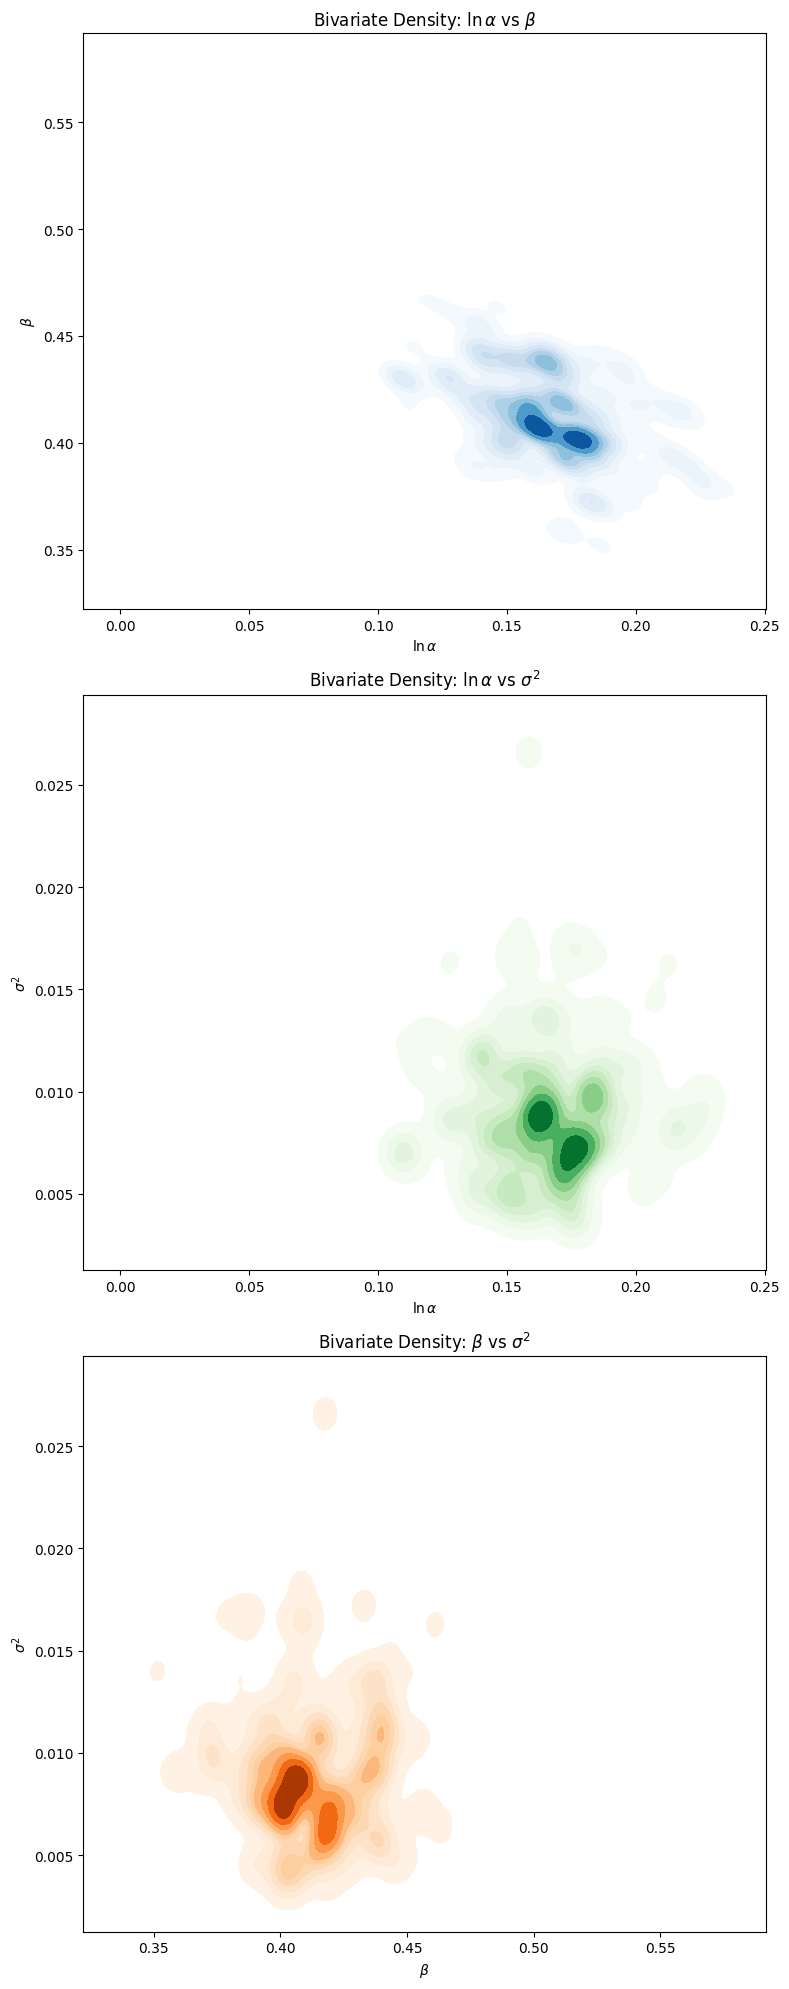

In [ ]:
# Extract samples for each parameter
ln_a_samples = xs_samples[:, 0]
beta_samples = xs_samples[:, 1]
sigma2_samples = xs_samples[:, 2]

# 1. Plot Univariate Posterior Densities (Marginals)
fig, axes = plt.subplots(3, 1, figsize=(5, 15))

sns.kdeplot(ln_a_samples, ax=axes[0], fill=True, color='blue')
axes[0].set_title('Univariate Posterior Density: $\\ln\\alpha$')
axes[0].set_xlabel('$\\ln\\alpha$')
axes[0].set_ylabel('Density')

sns.kdeplot(beta_samples, ax=axes[1], fill=True, color='green')
axes[1].set_title('Univariate Posterior Density: $\\beta$')
axes[1].set_xlabel('$\\beta$')
axes[1].set_ylabel('Density')

sns.kdeplot(sigma2_samples, ax=axes[2], fill=True, color='red')
axes[2].set_title('Univariate Posterior Density: $\\sigma^2$')
axes[2].set_xlabel('$\\sigma^2$')
axes[2].set_ylabel('Density')

plt.tight_layout()
plt.show()

# 2. Plot Bivariate Posterior Densities
fig, axes = plt.subplots(3, 1, figsize=(5, 15))

# ln(alpha) vs beta
sns.kdeplot(x=ln_a_samples, y=beta_samples, ax=axes[0], fill=True, cmap='Blues', thresh=0.05, levels=10)
axes[0].set_title('Bivariate Density: $\\ln\\alpha$ vs $\\beta$')
axes[0].set_xlabel('$\\ln\\alpha$')
axes[0].set_ylabel('$\\beta$')

# ln(alpha) vs sigma^2
sns.kdeplot(x=ln_a_samples, y=sigma2_samples, ax=axes[1], fill=True, cmap='Greens', thresh=0.05, levels=10)
axes[1].set_title('Bivariate Density: $\\ln\\alpha$ vs $\\sigma^2$')
axes[1].set_xlabel('$\\ln\\alpha$')
axes[1].set_ylabel('$\\sigma^2$')

# beta vs sigma^2
sns.kdeplot(x=beta_samples, y=sigma2_samples, ax=axes[2], fill=True, cmap='Oranges', thresh=0.05, levels=10)
axes[2].set_title('Bivariate Density: $\\beta$ vs $\\sigma^2$')
axes[2].set_xlabel('$\\beta$')
axes[2].set_ylabel('$\\sigma^2$')

plt.tight_layout()
plt.show()

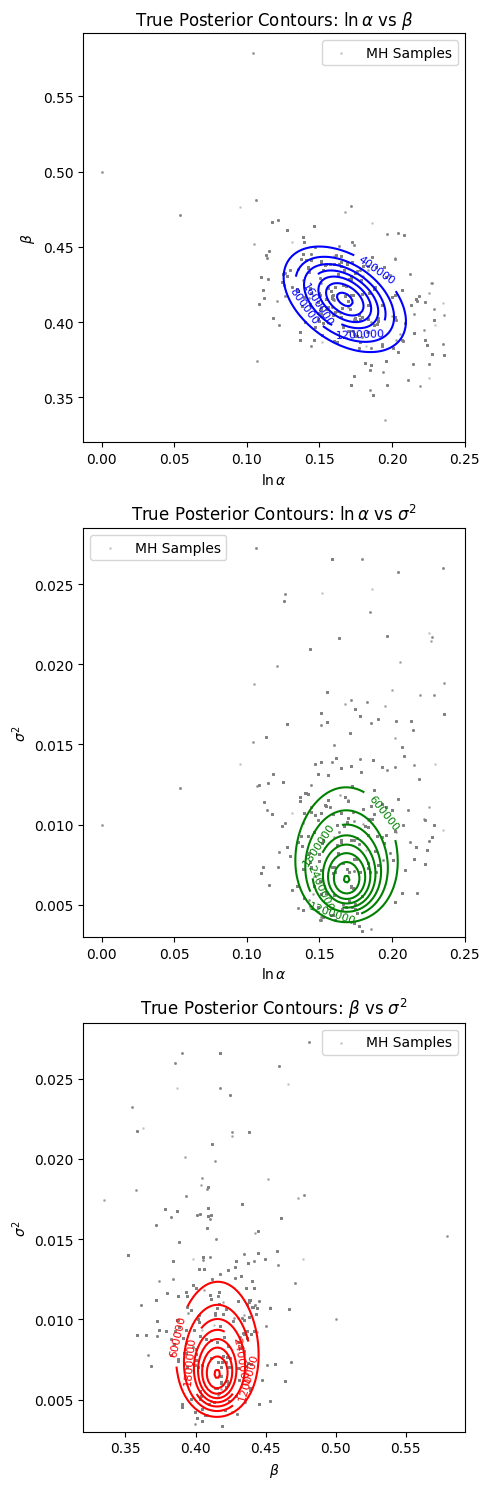

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1D grids for parameter evaluation based on sample ranges
ln_a_grid = np.linspace(0.08, 0.25, 100)
beta_grid = np.linspace(0.32, 0.50, 100)
sigma2_grid = np.linspace(0.003, 0.025, 100)

# Mean values from samples to fix the third parameter when plotting bivariates
ln_a_mean = np.mean(xs_samples[:, 0])
beta_mean = np.mean(xs_samples[:, 1])
sigma2_mean = np.mean(xs_samples[:, 2])

# Plotting Bivariate True Posterior Contours over MCMC Samples
fig, axes = plt.subplots(3, 1, figsize=(5, 15))

# --- Panel 1: ln(alpha) vs beta (evaluated at sigma2_mean) ---
# Evaluate posterior on grid
A, B = np.meshgrid(ln_a_grid, beta_grid)
Z = np.zeros_like(A)
for idx_i in range(A.shape[0]):
    for idx_j in range(A.shape[1]):
        # theta = (ln_a, b, var)
        val = posterior([A[idx_i, idx_j], B[idx_i, idx_j], sigma2_mean], data)
        Z[idx_i, idx_j] = float(np.squeeze(val))

axes[0].scatter(xs_samples[:, 0], xs_samples[:, 1], color='gray', alpha=0.3, s=1, label='MH Samples')
contour1 = axes[0].contour(A, B, Z, levels=8, colors='blue', linewidths=1.5)
axes[0].clabel(contour1, inline=True, fontsize=8)
axes[0].set_title(r'True Posterior Contours: $\ln\alpha$ vs $\beta$')
axes[0].set_xlabel(r'$\ln\alpha$')
axes[0].set_ylabel(r'$\beta$')
axes[0].legend()

# --- Panel 2: ln(alpha) vs sigma^2 (evaluated at beta_mean) ---
A, S = np.meshgrid(ln_a_grid, sigma2_grid)
Z = np.zeros_like(A)
for idx_i in range(A.shape[0]):
    for idx_j in range(A.shape[1]):
        val = posterior([A[idx_i, idx_j], beta_mean, S[idx_i, idx_j]], data)
        Z[idx_i, idx_j] = float(np.squeeze(val))

axes[1].scatter(xs_samples[:, 0], xs_samples[:, 2], color='gray', alpha=0.3, s=1, label='MH Samples')
contour2 = axes[1].contour(A, S, Z, levels=8, colors='green', linewidths=1.5)
axes[1].clabel(contour2, inline=True, fontsize=8)
axes[1].set_title(r'True Posterior Contours: $\ln\alpha$ vs $\sigma^2$')
axes[1].set_xlabel(r'$\ln\alpha$')
axes[1].set_ylabel(r'$\sigma^2$')
axes[1].legend()

# --- Panel 3: beta vs sigma^2 (evaluated at ln_a_mean) ---
B, S = np.meshgrid(beta_grid, sigma2_grid)
Z = np.zeros_like(B)
for idx_i in range(B.shape[0]):
    for idx_j in range(B.shape[1]):
        val = posterior([ln_a_mean, B[idx_i, idx_j], S[idx_i, idx_j]], data)
        Z[idx_i, idx_j] = float(np.squeeze(val))

axes[2].scatter(xs_samples[:, 1], xs_samples[:, 2], color='gray', alpha=0.3, s=1, label='MH Samples')
contour3 = axes[2].contour(B, S, Z, levels=8, colors='red', linewidths=1.5)
axes[2].clabel(contour3, inline=True, fontsize=8)
axes[2].set_title(r'True Posterior Contours: $\beta$ vs $\sigma^2$')
axes[2].set_xlabel(r'$\beta$')
axes[2].set_ylabel(r'$\sigma^2$')
axes[2].legend()

plt.tight_layout()
plt.show()